# Evaluation example (CAFA-evaluator)

Evaluates `predictions.csv` (random predictions for the whole test split) separately for BP, MF and CC.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "evaluation":
    os.chdir("..")

from projekt.cafa_evaluator import CafaEvaluator
from projekt.cafa_input_files import CafaInputFiles

## 1. Prepare input files

Ground truth is obtained from `test.tsv`, information accretion (needed for S-min) is obtained from `train.tsv`, predictions are converted from `predictions.csv` to CAFA-compatibile format.

In [2]:
input_files = CafaInputFiles(obo_file="data/go-basic.obo", work_dir="evaluation")
input_files.write_ground_truth("data/splits/test.tsv")
input_files.write_information_accretion("data/splits/train.tsv")
input_files.write_predictions("predictions.csv")

evaluator = CafaEvaluator(input_files)

## 2. Evaluate

This stage may take some tome due to millions of prediction rows.

In [3]:
evaluator.evaluate(n_cpu=4)

n         tp            fp  \
filename        ns                 tau                                     
predictions.tsv biological_process 0.01  1568.0  39.904337  12128.900510   
                                   0.02  1568.0  39.888393  12068.127551   
                                   0.03  1568.0  39.867985  12007.061224   
                                   0.04  1568.0  39.847577  11945.445791   
                                   0.05  1568.0  39.829082  11883.287628   
...                                         ...        ...           ...   
                cellular_component 0.95  1700.0  13.807059    262.928235   
                                   0.96  1700.0  13.492941    225.628235   
                                   0.97  1700.0  13.105294    184.462941   
                                   0.98  1700.0  12.454706    138.115882   
                                   0.99  1700.0  11.154706     82.909412   

                                               fn        pr        rc  cov  \
filename        ns                 tau                                       
predictions.tsv biological_process 0.01  0.176658  0.003279  0.996337  1.0   
                                   0.02  0.192602  0.003294  0.996140  1.0   
                                   0.03  0.213010  0.003309  0.995544  1.0   
                                   0.04  0.233418  0.003325  0.995152  1.0   
                                   0.05  0.251913  0.003341  0.994803  1.0   
...                                           ...       ...       ...  ...   
                cellular_component 0.95  2.605294  0.050164  0.876093  1.0   
                                   0.96  2.919412  0.056859  0.860785  1.0   
                                   0.97  3.307059  0.067043  0.841507  1.0   
                                   0.98  3.957647  0.083947  0.808324  1.0   
                                   0.99  5.257647  0.122300  0.738078  1.0   

                                                   mi        ru         f  \
filename        ns                 tau                                      
predictions.tsv biological_process 0.01  12128.900510  0.176658  0.006537   
                                   0.02  12068.127551  0.192602  0.006567   
                                   0.03  12007.061224  0.213010  0.006597   
                                   0.04  11945.445791  0.233418  0.006627   
                                   0.05  11883.287628  0.251913  0.006659   
...                                               ...       ...       ...   
                cellular_component 0.95    262.928235  2.605294  0.094895   
                                   0.96    225.628235  2.919412  0.106671   
                                   0.97    184.462941  3.307059  0.124191   
                                   0.98    138.115882  3.957647  0.152098   
                                   0.99     82.909412  5.257647  0.209830   

                                         ...      pr_w      rc_w  cov_w  \
filename        ns                 tau   ...                              
predictions.tsv biological_process 0.01  ...  0.002002  0.999711    1.0   
                                   0.02  ...  0.002011  0.999554    1.0   
                                   0.03  ...  0.002020  0.998712    1.0   
                                   0.04  ...  0.002029  0.998553    1.0   
                                   0.05  ...  0.002039  0.998151    1.0   
...                                      ...       ...       ...    ...   
                cellular_component 0.95  ...  0.016639  0.800715    1.0   
                                   0.96  ...  0.019014  0.776540    1.0   
                                   0.97  ...  0.022614  0.743923    1.0   
                                   0.98  ...  0.028742  0.694780    1.0   
                                   0.99  ...  0.041476  0.586881    1.0   

                                                 mi_w      ru_w 

## 3. F-max and S-min per ontology

In [4]:
evaluator.summary()

F-max  F-max threshold       S-min  S-min threshold
filename        ns                                                        
predictions.tsv BP  0.064995             0.99  929.485705             0.99
                CC  0.209830             0.99  166.872291             0.99
                MF  0.063610             0.99  373.898604             0.99

## 4. Precision / recall / F1 for every threshold

In [5]:
evaluator.curves().head()

pr        rc         f
filename        ns                 tau                               
predictions.tsv biological_process 0.01  0.003279  0.996337  0.006537
                                   0.02  0.003294  0.996140  0.006567
                                   0.03  0.003309  0.995544  0.006597
                                   0.04  0.003325  0.995152  0.006627
                                   0.05  0.003341  0.994803  0.006659

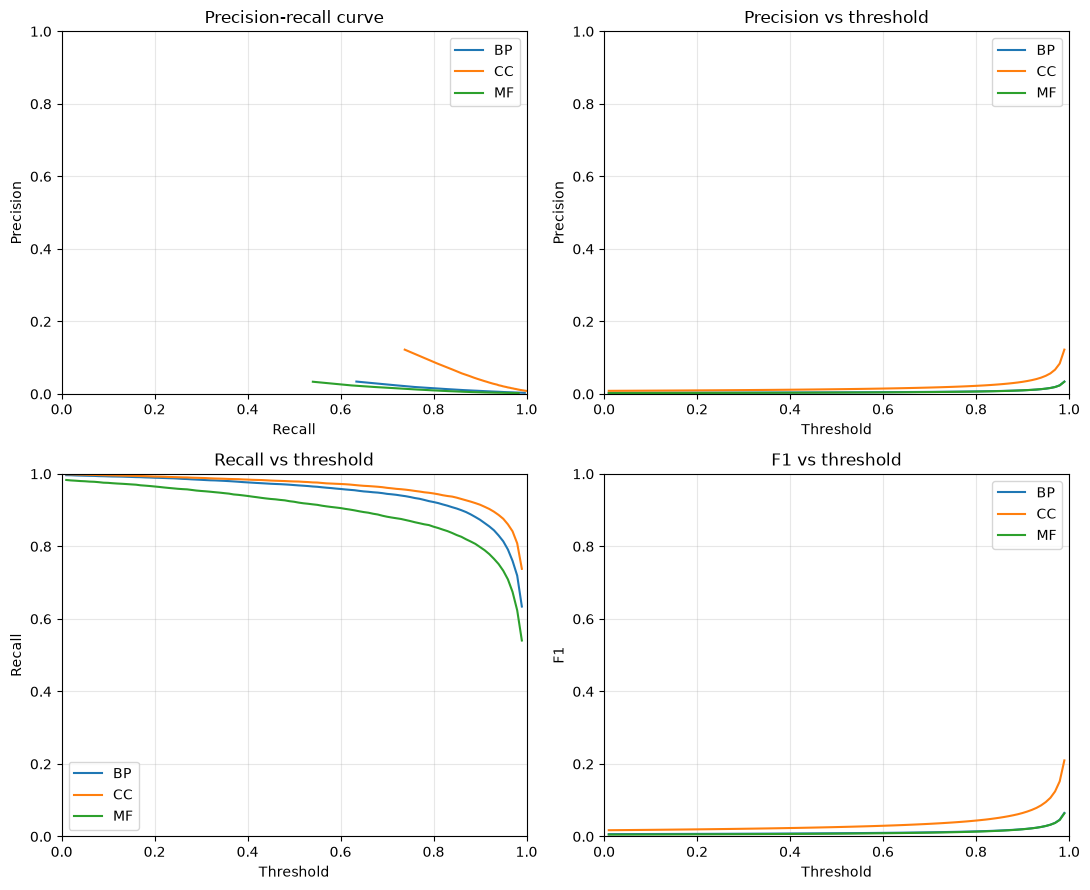

In [9]:
evaluator.plot_curves();

## 5. Save everything to `evaluation/results/`

PosixPath('evaluation/results')

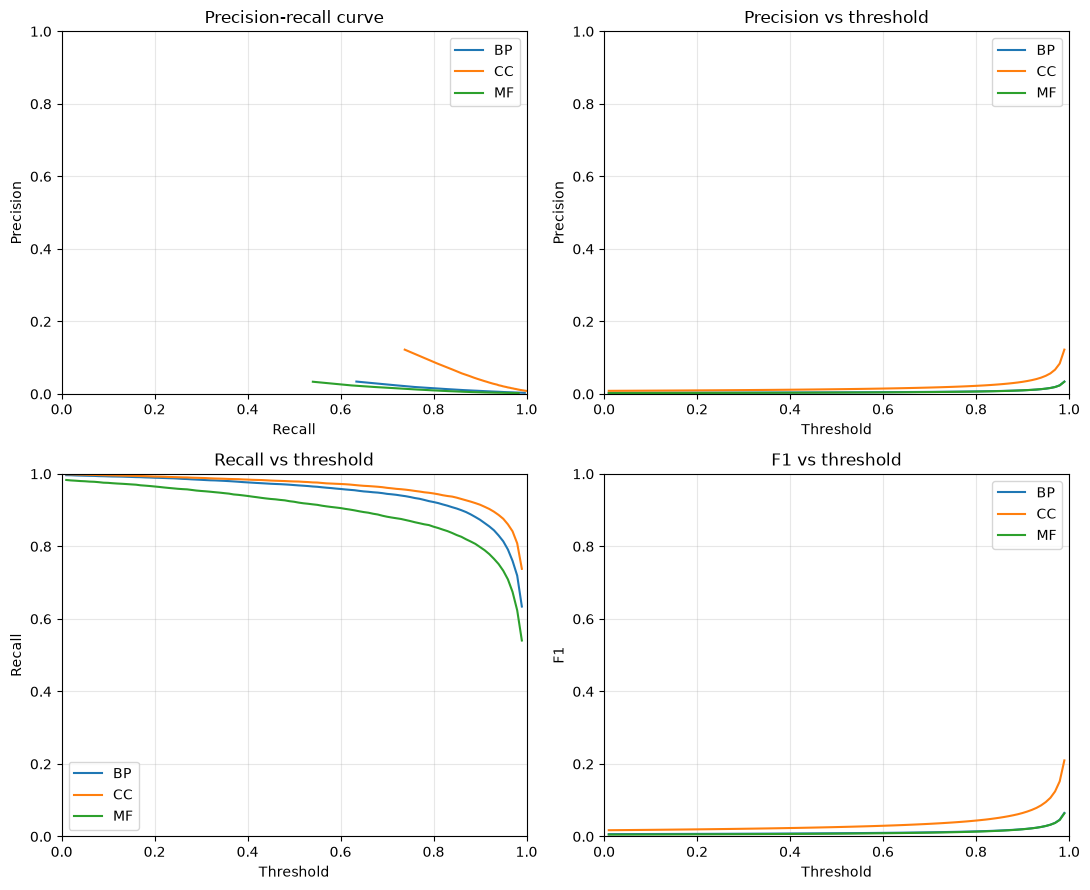

In [7]:
evaluator.save_results()